In [103]:
import numpy as np
from numpy.linalg import eigh, cholesky
import matplotlib.pyplot as plt
from scipy.linalg import logm

In [104]:
def gradient_riemannian_mean(X_k, As, ws):

  #need to calculate X−1/2 log(X1/2A−1X1/2)X1/2

  G = np.zeros_like(X_k)
  lam, B = eigh(X_k)
  X_half = B @ np.diag(np.sqrt(np.maximum(lam, 1e-12))) @ B.T
  X_neg_half = B @ np.diag(1 / np.sqrt(np.maximum(lam, 1e-12))) @ B.T

  for Ai, wi in zip(As, ws):
    A_inv = np.linalg.inv(Ai)
    M = X_half @ A_inv @ X_half
    lam_M, BM = eigh(M)
    lam_M = np.maximum(lam_M, 1e-12)
    log_M = BM @ np.diag(np.log(lam_M)) @ BM.T

    G += wi * X_neg_half @ log_M @ X_half
  return G

def riemannian_linear_oracle(G, L, U):
  lam, Q = eigh(G)

  L_hat = Q.T @ L @ Q
  U_hat = Q.T @ U @ Q

  M = .5 * (U_hat - L_hat + (U_hat - L_hat).T)
  P = cholesky(M)  

  sign = np.sign(lam)
  diag_sign = np.maximum(-sign, 0.0)
  D = np.diag(diag_sign)

  Z_hat = P.T @ D @ P + U_hat
  Z = Q @ Z_hat @ Q.T

  return Z

def geo_mean(X, Z, alpha):
  lam, B = eigh(X)
  X_half = B @ np.diag(np.sqrt(lam)) @ B.T
  X_neg_half = B @ np.diag(1 / np.sqrt(lam)) @ B.T

  M = X_neg_half @ Z @ X_neg_half
  lam_M, B_M = eigh(M)
  lam_M = np.maximum(lam_M, 1e-12)
  M_alpha = B_M @ np.diag(lam_M ** alpha) @ B_M.T

  return X_half @ M_alpha @ X_half

def compute_bounds(As, ws):
  L = np.zeros_like(As[0])
  U = np.zeros_like(As[0])

  for Ai, wi in zip(As, ws):
    L += wi * np.linalg.inv(Ai)
    U += wi * Ai

  L = np.linalg.inv(L)

  return L, U

def riemannian_distance(X,Y):
  lam, B = eigh(X)
  lam = np.maximum(lam, 1e-12)
  X_neg_half = B @ np.diag(1 / np.sqrt(lam)) @ B.T

  M = X_neg_half @ Y @ X_neg_half
  lam_M, _ = eigh(M)
  lam_M = np.maximum(lam_M, 1e-12)

  return np.sqrt(np.sum(np.log(lam_M) ** 2))


In [105]:
def riemannian_frank_wolfe_geometric_mean(As, ws, X0, max_iters=5000, X_true = None):
  X_k = X0
  errors = []

  L, U = compute_bounds(As, ws)

  for k in range(max_iters):
    if X_true is not None:
      errors.append(riemannian_distance(X_k, X_true))

    G = gradient_riemannian_mean(X_k, As, ws)
    Z_k = riemannian_linear_oracle(G, L, U)
    alpha_k = 2 / (k + 2)
    X_k = geo_mean(X_k, Z_k, alpha_k)
  X_bar = X_k 

  return X_bar, errors

In [117]:
N = 100 
n = 5 

random_state = 42
np.random.seed(random_state) 

As = [] 
ws = [] 

for i in range(N): 
    A = np.random.rand(n, n) 
    A = A @ A.T + np.eye(n) * 1e-3 
    w = np.random.rand() 
    As.append(A) 
    ws.append(w) 

ws = np.array(ws) / np.sum(ws)

In [108]:
def matrix_geometric_mean_reference(As, ws, max_iters=200):
    """Gradient descent on the Riemannian manifold as reference solution."""
    X = As[0].copy()
    for _ in range(max_iters):
        G = gradient_riemannian_mean(X, As, ws)
        lam, B = eigh(X)
        X_half = B @ np.diag(np.sqrt(np.maximum(lam, 1e-12))) @ B.T
        X = geo_mean(X, X - 0.01 * X_half @ G @ X_half, 1.0)  # small step
    return X

In [118]:

# Get reference solution (run longer to convergence)
X_true = matrix_geometric_mean_reference(As, ws, max_iters=500)

# Run FW with error tracking
X_bar, errors = riemannian_frank_wolfe_geometric_mean(As, ws, As[0], X_true=X_true)


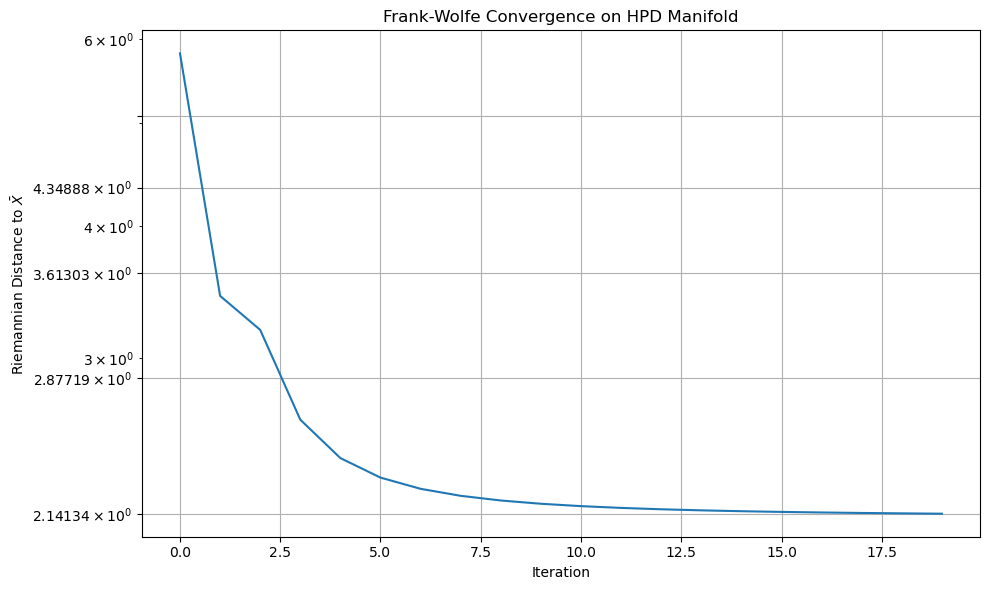

In [120]:
B = 20
# Plot
plt.figure(figsize=(10, 6))
plt.semilogy(errors[0:B])
plt.yticks(np.arange(np.min(errors[0:B]), np.max(errors[0:B]), step=(np.max(errors[0:B]) - np.min(errors[0:B]))/5))
plt.xlabel("Iteration")
plt.ylabel("Riemannian Distance to $\\bar{X}$")
plt.title("Frank-Wolfe Convergence on HPD Manifold")
plt.grid(True)
plt.tight_layout()
plt.show()